# 01 · Exploratory data analysis: C-MAPSS FD001

FD001 is the simplest subset: **one operating condition** and **one fault mode** (HPC
degradation), per [`docs/dataset.md`](../docs/dataset.md). This notebook uses **training data
only**. The test files are never opened, so nothing we decide here leaks information from the
test set.

Questions:

1. How many engines are there, and how long do they live?
2. Which sensors carry no information (constant or near-constant)?
3. How do the remaining sensors change as an engine approaches failure?
4. How strongly does each sensor correlate with remaining useful life (RUL)?
5. When does degradation become visible? This decides the RUL cap.
6. Does FD001 really have a single operating condition?

Data comes from our loader `predmaint.data.load`. Run
`uv run python -m predmaint.data.download` first.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from predmaint.data.load import SENSOR_COLUMNS, SETTING_COLUMNS, add_rul, load_train

BLUE = "#2a78d6"  # primary series
RED = "#e34948"  # opposite pole (positive correlation)
GRAY = "#8a8984"  # context lines
INK = "#52514e"  # secondary text / reference lines

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": "#e6e5e1",
        "grid.linewidth": 0.6,
        "axes.edgecolor": INK,
        "axes.labelcolor": INK,
        "xtick.color": INK,
        "ytick.color": INK,
        "axes.titlesize": 10,
        "axes.labelsize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
    }
)
pd.set_option("display.precision", 4)

train = add_rul(load_train("FD001"))
train.head()

,unit,cycle,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,...,s_13,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21,rul
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187


## 1. Overview

In [2]:
lifetimes = train.groupby("unit")["cycle"].max().rename("lifetime")
print(f"engines: {train['unit'].nunique()}")
print(f"rows:    {len(train)}")
print(f"columns: {train.shape[1]} (26 raw + rul)")
print(f"missing values: {int(train.isna().sum().sum())}")
lifetimes.describe()

engines: 100
rows:    20631
columns: 27 (26 raw + rul)
missing values: 0


count    100.0000
mean     206.3100
std       46.3427
min      128.0000
25%      177.0000
50%      199.0000
75%      229.2500
max      362.0000
Name: lifetime, dtype: float64

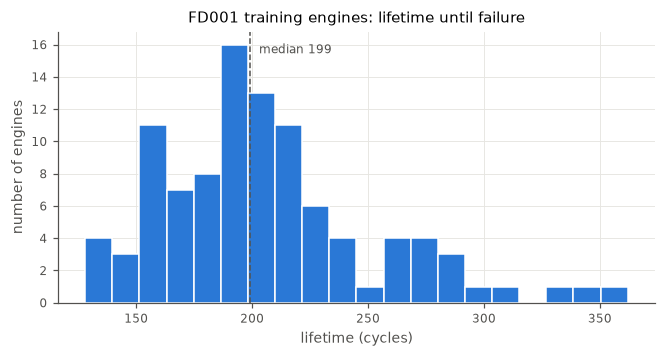

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(lifetimes, bins=20, color=BLUE, edgecolor="white", linewidth=1)
ax.axvline(lifetimes.median(), color=INK, linestyle="--", linewidth=1)
ax.annotate(
    f"median {lifetimes.median():.0f}",
    xy=(lifetimes.median(), ax.get_ylim()[1] * 0.92),
    xytext=(6, 0),
    textcoords="offset points",
    fontsize=8,
    color=INK,
)
ax.set_title("FD001 training engines: lifetime until failure")
ax.set_xlabel("lifetime (cycles)")
ax.set_ylabel("number of engines")
plt.show()

**Findings**

- **Size.** 100 engines and 20,631 rows (26 raw columns plus `rul`), with **no missing values**.
- **Lifetimes vary a lot.** The shortest engine lasts **128** cycles, the median **199** and the longest **362** (mean 206.3, std 46.3).
- **Long right tail.** The middle half of engines fail between 177 and 229 cycles, but a few run past 300.
- **Why the 128-cycle minimum matters.** Every engine has at least 128 rows, so every RUL value from 0 to 127 appears for all 100 engines. Section 5 uses this.

## 2. Constant and near-constant sensors

A sensor that never changes cannot tell a healthy engine from a failing one. We check three
statistics per sensor:

- the standard deviation;
- the number of distinct values;
- the correlation with RUL.

The coefficient of variation (std ÷ mean) is also shown, because it is a common but misleading
choice of rule for this data.

In [4]:
sensor_stats = pd.DataFrame(
    {
        "std": train[SENSOR_COLUMNS].std(),
        "n_unique": train[SENSOR_COLUMNS].nunique(),
        "cv": train[SENSOR_COLUMNS].std() / train[SENSOR_COLUMNS].mean().abs(),
        "corr_rul": train[SENSOR_COLUMNS].corrwith(train["rul"]),
    }
)
sensor_stats

,std,n_unique,cv,corr_rul
s_1,0.0000e+00,1,0.0000e+00,NaN
s_2,5.0005e-01,310,7.7807e-04,-6.0648e-01
s_3,6.1311e+00,3012,3.8548e-03,-5.8452e-01
s_4,9.0006e+00,4051,6.3882e-03,-6.7895e-01
s_5,5.3292e-15,1,3.6451e-16,6.4091e-17
s_6,1.3890e-03,2,6.4276e-05,-1.2835e-01
s_7,8.8509e-01,513,1.5995e-03,6.5722e-01
s_8,7.0985e-02,53,2.9725e-05,-5.6397e-01
s_9,2.2083e+01,6403,2.4360e-03,-3.9010e-01
s_10,0.0000e+00,1,0.0000e+00,NaN


In [5]:
constant = sensor_stats.index[sensor_stats["n_unique"] == 1].tolist()
two_valued = sensor_stats.index[sensor_stats["n_unique"] == 2].tolist()
print("constant (1 distinct value):", constant)
print("two distinct values:        ", two_valued)
for s in two_valued:
    print(f"\n{s} value counts:")
    print(train[s].value_counts().to_string())

constant (1 distinct value): ['s_1', 's_5', 's_10', 's_16', 's_18', 's_19']
two distinct values:         ['s_6']

s_6 value counts:
s_6
21.61    20225
21.60      406


In [6]:
# Does the minority value of the two-valued sensor(s) relate to RUL?
for s in two_valued:
    minority = train[s].value_counts().idxmin()
    rul_minority = train.loc[train[s] == minority, "rul"]
    rul_majority = train.loc[train[s] != minority, "rul"]
    print(
        f"{s}: minority value {minority} occurs in {rul_minority.size} rows, "
        f"{train.loc[train[s] == minority, 'unit'].nunique()} engines; "
        f"median RUL there {rul_minority.median():.0f} vs {rul_majority.median():.0f} elsewhere"
    )

s_6: minority value 21.6 occurs in 406 rows, 62 engines; median RUL there 171 vs 101 elsewhere


**Findings**

- **Constant sensors.** `s_1`, `s_5`, `s_10`, `s_16`, `s_18` and `s_19` have a **single distinct value** in all 20,631 rows, so they carry no information. `s_5` and `s_16` show a std of 5.3e-15 and 3.5e-18 rather than exactly 0. That is floating-point rounding, so testing `std == 0` would miss them, and counting distinct values is the reliable test.
- **`s_6` is nearly constant.** It has two values: 21.61 in 20,225 rows and 21.60 in 406 rows (2%), one rounding step apart. The rarer value appears in 62 engines, at a median RUL of 171 versus 101 elsewhere, so it leans slightly towards early life. Its correlation with RUL is only −0.13. We treat it as near-zero variance and drop it. This is a judgement call worth revisiting.
- **The coefficient of variation (std ÷ mean) is misleading here.** `s_8` and `s_13` have a *lower* CV (3.0e-5) than `s_6` (6.4e-5), yet each correlates −0.56 with RUL. They are recorded to only 0.01 resolution around a large mean (about 2388), so their relative spread looks tiny even though they are informative. Never drop sensors on CV alone.

In [7]:
near_zero_variance = constant + two_valued
informative = [s for s in SENSOR_COLUMNS if s not in near_zero_variance]
print("drop:", near_zero_variance)
print("keep:", informative, f"({len(informative)} sensors)")

drop: ['s_1', 's_5', 's_10', 's_16', 's_18', 's_19', 's_6']
keep: ['s_2', 's_3', 's_4', 's_7', 's_8', 's_9', 's_11', 's_12', 's_13', 's_14', 's_15', 's_17', 's_20', 's_21'] (14 sensors)


## 3. Degradation trajectories

Each informative sensor is plotted against RUL for 10 engines, units 1–10, a fixed choice so the
plot is reproducible. The x-axis is reversed, so time runs left to right and **failure (RUL 0)
is on the right**.

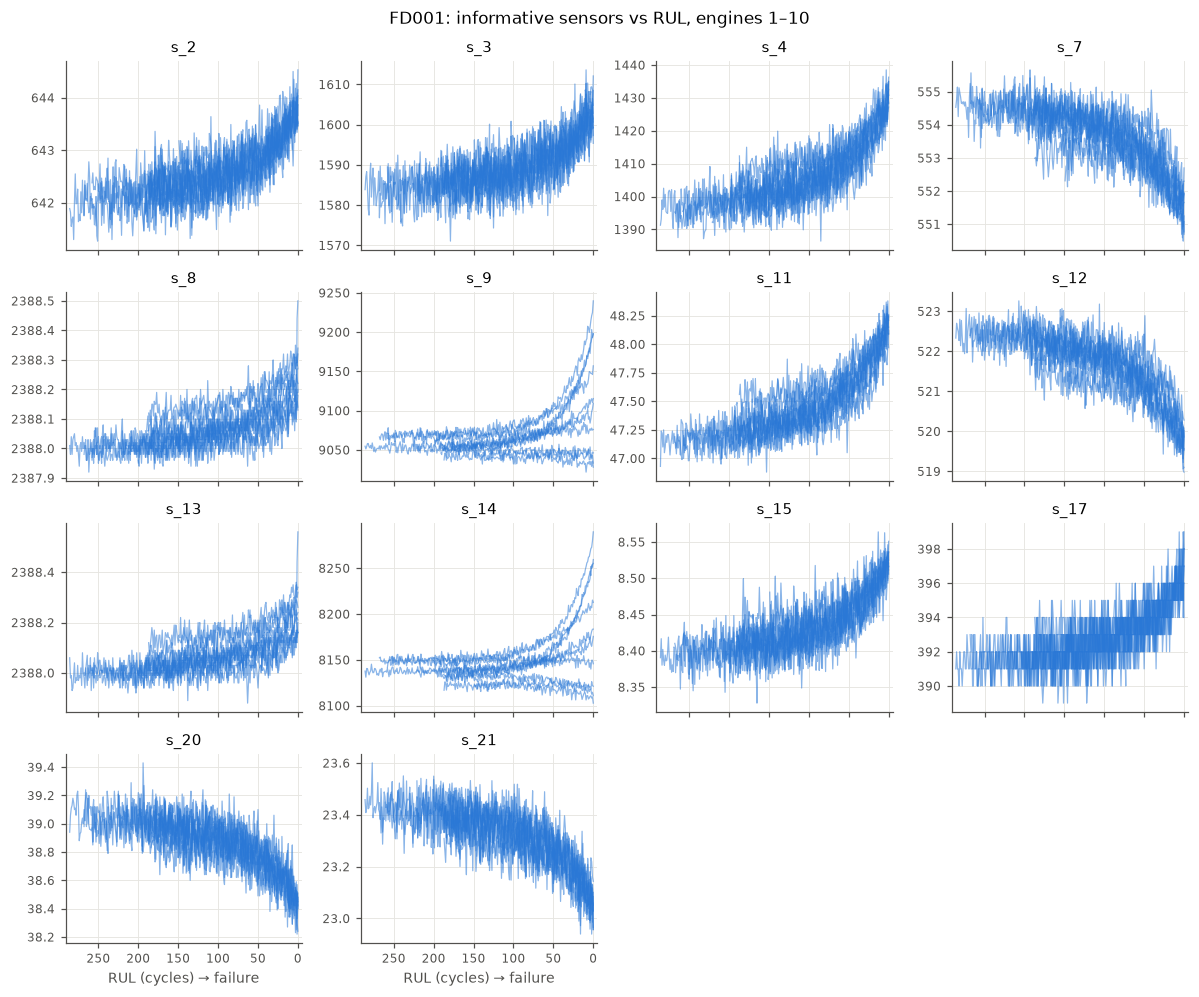

In [8]:
sample_units = list(range(1, 11))
sample = train[train["unit"].isin(sample_units)]

ncols = 4
nrows = int(np.ceil(len(informative) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(11, 2.3 * nrows), sharex=True)
for ax, s in zip(axes.flat, informative, strict=False):
    for _, g in sample.groupby("unit"):
        ax.plot(g["rul"], g[s], color=BLUE, linewidth=0.8, alpha=0.55)
    ax.set_title(s)
    ax.ticklabel_format(axis="y", useOffset=False)
axes.flat[0].set_xlim(sample["rul"].max() + 5, -5)  # shared x-axis: reverse once, failure right
for ax in axes.flat[len(informative) :]:
    ax.set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel("RUL (cycles) → failure")
fig.suptitle("FD001: informative sensors vs RUL, engines 1–10", fontsize=11)
fig.tight_layout()
plt.show()

In [9]:
# Do all engines move the same way? Per engine: mean of the last 10 cycles minus mean of the
# first 30 cycles, in units of the sensor's overall std. "agree" = share of engines whose change
# has the same sign as the fleet-wide trend (opposite sign of the correlation with RUL).
first = train[train["cycle"] <= 30].groupby("unit")[informative].mean()
last = train[train["rul"] < 10].groupby("unit")[informative].mean()
change = (last - first) / train[informative].std()
trend = -np.sign(sensor_stats.loc[informative, "corr_rul"])
consistency = pd.DataFrame(
    {
        "agree": (np.sign(change) == trend).mean(),
        "median_change_std": (change * trend).median(),
    }
).sort_values("agree")
consistency.round(2).T

,s_14,s_9,s_2,s_3,s_4,s_7,s_8,s_11,s_12,s_13,s_15,s_17,s_20,s_21
agree,0.58,0.71,1.0,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
median_change_std,0.60,0.91,2.4,2.34,2.74,2.59,2.26,2.72,2.65,2.29,2.57,2.43,2.57,2.46


**Findings**

- **12 sensors share a clear, consistent pattern.** They are roughly flat early in life and change faster as failure approaches.
  - *Rising towards failure:* `s_2`, `s_3`, `s_4`, `s_8`, `s_11`, `s_13`, `s_15`, `s_17`.
  - *Falling towards failure:* `s_7`, `s_12`, `s_20`, `s_21`.
  - For all 12, **100% of the 100 engines** move in the fleet direction between the first 30 cycles and the last 10. The median change is 2.26–2.74 std.
- **`s_9` and `s_14` behave differently.** In the plot, the 10 engines split near failure: some rise steeply while others stay flat or fall. Across all engines, only **71%** (`s_9`) and **58%** (`s_14`) move in the fleet direction, with a median change of only 0.91 and 0.60 std. For `s_14`, that is little better than a coin flip.
- **Coarse recording.** `s_17` takes only 13 distinct values, which shows as steps. `s_8` and `s_13` (53 and 56 distinct values) show visible banding.

## 4. Correlation with RUL

This is the Pearson correlation between each informative sensor and the uncapped RUL, across
all training rows. Pearson measures only *linear* association, so a sensor that changes only
near failure can score lower than its usefulness suggests. Section 5 looks at that shape
directly.

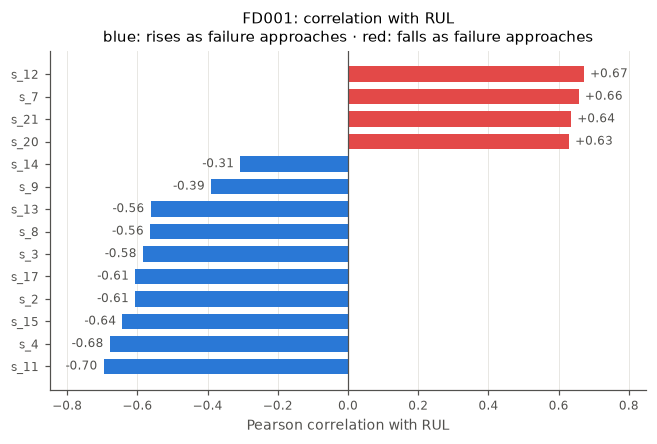

,s_11,s_4,s_15,s_2,s_17,s_3,s_8,s_13,s_9,s_14,s_20,s_21,s_7,s_12
corr_rul,-0.6962,-0.6789,-0.6427,-0.6065,-0.6062,-0.5845,-0.564,-0.5626,-0.3901,-0.3068,0.6294,0.6357,0.6572,0.672


In [10]:
corr = sensor_stats.loc[informative, "corr_rul"].sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
colors = [BLUE if v < 0 else RED for v in corr]
ax.barh(corr.index, corr.values, color=colors, height=0.7)
ax.axvline(0, color=INK, linewidth=0.8)
for y, v in enumerate(corr.values):
    ax.annotate(
        f"{v:+.2f}",
        xy=(v, y),
        xytext=(-4 if v < 0 else 4, 0),
        textcoords="offset points",
        ha="right" if v < 0 else "left",
        va="center",
        fontsize=8,
        color=INK,
    )
ax.set_xlim(-0.85, 0.85)
ax.set_xlabel("Pearson correlation with RUL")
ax.set_title(
    "FD001: correlation with RUL\n"
    "blue: rises as failure approaches · red: falls as failure approaches"
)
ax.grid(axis="y", visible=False)
plt.show()
corr.to_frame("corr_rul").T

**Findings**

- **12 sensors have |r| between 0.56 and 0.70.** The strongest are `s_11` (−0.70), `s_4` (−0.68), `s_12` (+0.67) and `s_7` (+0.66).
- **`s_9` (−0.39) and `s_14` (−0.31) are clearly the weakest.** This matches section 3: when engines disagree on direction, a single linear relationship is weak.
- **The signs match section 3.** The four sensors that fall towards failure (`s_7`, `s_12`, `s_20`, `s_21`) correlate positively with RUL; the rest correlate negatively.
- **Caveat: the cap will change these numbers.** These correlations use the uncapped RUL, and most change happens near failure (section 5). The numbers say which sensors matter, not how well a model will do.

## 5. Degradation onset and the RUL cap

To see *when* degradation starts, the sensors are combined across all 100 engines in four steps:

1. Standardise each informative sensor (z-score over the training set).
2. Flip its sign where the correlation with RUL is positive. Every sensor then *rises* as
   failure approaches.
3. Average each sensor over all rows that share the same RUL value.
4. Smooth with a centred rolling mean over 15 RUL values.

Only engines that lived at least *r + 1* cycles have a row at RUL *r*. The lower panel shows
how many engines contribute at each RUL.

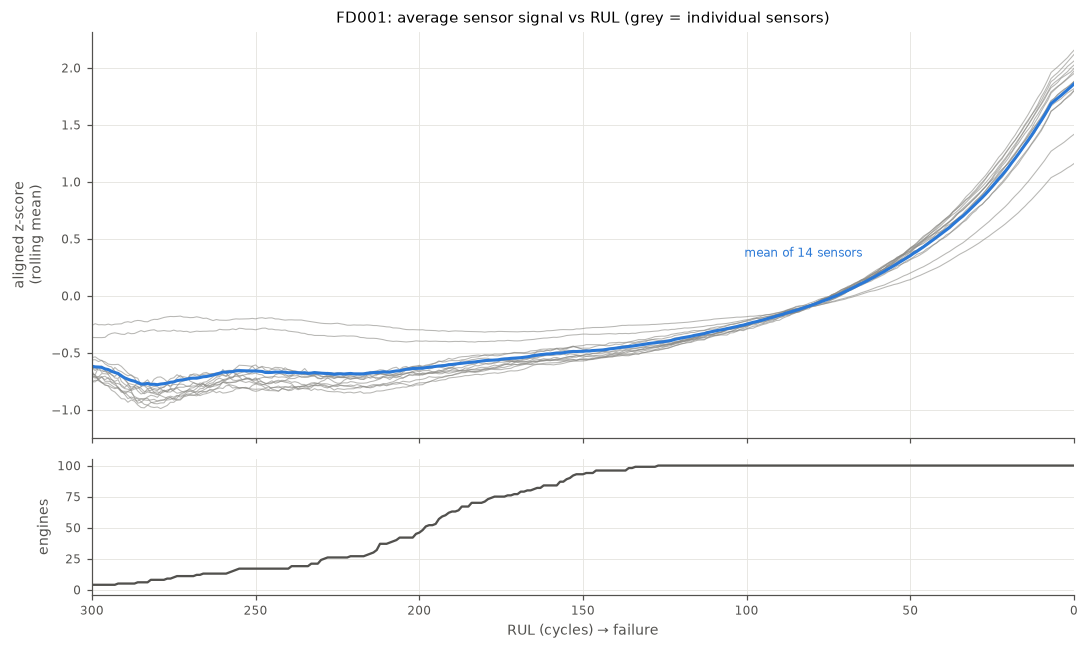

In [11]:
z = (train[informative] - train[informative].mean()) / train[informative].std()
z = z * -np.sign(sensor_stats.loc[informative, "corr_rul"])  # degradation direction = up
z["rul"] = train["rul"]

by_rul = z.groupby("rul")[informative].mean()
smoothed = by_rul.rolling(15, center=True, min_periods=8).mean()
health = smoothed.mean(axis=1).rename("mean of aligned sensors")
n_engines = train.groupby("rul")["unit"].nunique()

max_rul = 300
fig, (ax, ax_n) = plt.subplots(
    2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]}
)
for s in informative:
    ax.plot(smoothed.index, smoothed[s], color=GRAY, linewidth=0.7, alpha=0.6)
ax.plot(health.index, health, color=BLUE, linewidth=2)
ax.annotate(
    f"mean of {len(informative)} sensors",
    xy=(60, health.loc[60]),
    xytext=(-10, 12),
    textcoords="offset points",
    ha="right",
    fontsize=8,
    color=BLUE,
)
ax.set_ylabel("aligned z-score\n(rolling mean)")
ax.set_title("FD001: average sensor signal vs RUL (grey = individual sensors)")
ax_n.plot(n_engines.index, n_engines.values, color=INK, linewidth=1.5)
ax_n.set_ylabel("engines")
ax_n.set_xlabel("RUL (cycles) → failure")
ax_n.set_xlim(max_rul, 0)
fig.tight_layout()
plt.show()

In [12]:
print(
    "engines contributing at RUL 0 / 127 / 128 / 150 / 200 / 250:",
    [int(n_engines.get(r, 0)) for r in (0, 127, 128, 150, 200, 250)],
)
print("sensors furthest from the pack at RUL 250:")
print(smoothed.loc[250].sort_values(ascending=False).head(3).round(2).to_string())

engines contributing at RUL 0 / 127 / 128 / 150 / 200 / 250: [100, 100, 99, 93, 46, 17]
sensors furthest from the pack at RUL 250:
s_14   -0.20
s_9    -0.30
s_17   -0.61


In [13]:
# Onset as "share of the total rise already reached".
# baseline = average signal on the flat stretch RUL 200-250; total rise = signal at RUL 0 - baseline
baseline = health.loc[200:250].mean()
total_rise = health.loc[0] - baseline
share = ((health - baseline) / total_rise).rename("share of total rise")
checkpoints = [250, 200, 175, 150, 140, 130, 125, 120, 110, 100, 75, 50, 25, 0]
print(f"baseline {baseline:.3f}, at failure {health.loc[0]:.3f}, total rise {total_rise:.3f}")
pd.DataFrame({"signal": health.loc[checkpoints], "share": share.loc[checkpoints]}).round(3).T

baseline -0.671, at failure 1.859, total rise 2.530


rul,250,200,175,150,140,130,125,120,110,100,75,50,25,0
signal,-0.660,-0.636,-0.557,-0.488,-0.459,-0.419,-0.401,-0.371,-0.311,-0.249,-0.028,0.352,0.959,1.859
share,0.004,0.014,0.045,0.073,0.084,0.100,0.107,0.119,0.142,0.167,0.254,0.404,0.644,1.000


In [14]:
# Largest RUL from which the signal stays above X % of the total rise all the way to failure.
for pct in (5, 10, 20):
    above = (share > pct / 100).sort_index()  # index: RUL 0, 1, 2, ...
    stays = above.astype(int).cummin().astype(bool)  # True while every RUL <= r is above
    print(f"stays above {pct:>2}% of the total rise from RUL {stays[stays].index.max()} to failure")

stays above  5% of the total rise from RUL 169 to failure
stays above 10% of the total rise from RUL 129 to failure
stays above 20% of the total rise from RUL 89 to failure


**Findings**

- **Far from failure, the average rests on fewer engines.** All 100 engines contribute up to RUL 127, then the count falls: 99 at 128, 93 at 150, 46 at 200 and 17 at 250. Averages far from failure come from fewer, longer-lived engines.
- **The averaged signal is flat between RUL 250 and 200** (0.4% and 1.4% of its total rise).
- **Then it rises slowly:** 7.3% of the total rise at RUL 150 and 10% at RUL 130.
- **Then it accelerates:** 16.7% at RUL 100, 40% at 50, 64% at 25. Roughly **90% of the change happens in the last ~130 cycles**.
- **Onset depends on the threshold.** The signal stays above 5% of its total rise from RUL **169**, above 10% from **129**, and above 20% from **89**.
- **The same two outliers.** The two grey lines far from the pack at RUL 250 are `s_14` (−0.20) and `s_9` (−0.30), the inconsistent sensors from sections 3–4.

**Recommendation: cap RUL at 125.**

1. **Above about 130 cycles, the sensors barely move.** Less than 10% of the total change has happened, so RUL 300 and RUL 200 look almost the same in the data (shares of 0.4% and 1.4%). Asking a model to tell them apart mostly teaches it noise.
2. **125 sits right at the 10% point** (share 0.107 at RUL 125). Our 5% and 20% thresholds give 169 and 89, so the right cap lies in a range and is a judgement call.
3. **All 100 engines cover the whole capped range,** because 125 ≤ 127. The target is not shaped by the few longest-lived engines.

Treat the cap as a **hyperparameter**. Confirm it on validation data and compare nearby values (e.g. 110–150) before fixing it.

## 6. Operating settings

The readme says FD001 has **one** operating condition (sea level). We check the three setting
columns directly.

In [15]:
print(train[SETTING_COLUMNS].describe().loc[["mean", "std", "min", "max"]])
print("\ndistinct values:", train[SETTING_COLUMNS].nunique().to_dict())
settings_corr = train[SETTING_COLUMNS[:2]].corrwith(train["rul"]).round(4)
print("\ncorrelation with RUL:", settings_corr.to_dict())

       setting_1   setting_2  setting_3
mean -8.8701e-06  2.3508e-06      100.0
std   2.1873e-03  2.9306e-04        0.0
min  -8.7000e-03 -6.0000e-04      100.0
max   8.7000e-03  6.0000e-04      100.0

distinct values: {'setting_1': 158, 'setting_2': 13, 'setting_3': 1}

correlation with RUL: {'setting_1': -0.0032, 'setting_2': -0.0019}


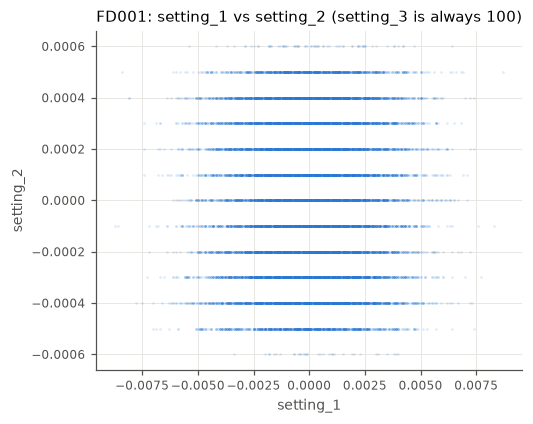

In [16]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(train["setting_1"], train["setting_2"], s=3, color=BLUE, alpha=0.15, linewidths=0)
ax.set_xlabel("setting_1")
ax.set_ylabel("setting_2")
ax.set_title("FD001: setting_1 vs setting_2 (setting_3 is always 100)")
plt.show()

**Findings**

- **`setting_3` is always 100** (one distinct value).
- **`setting_1` stays within ±0.0087** (std 0.0022, 158 distinct values).
- **`setting_2` stays within ±0.0006** (std 0.00029, 13 distinct values, in steps of 0.0001).
- **The scatter plot shows a single cloud centred on (0, 0).** There are no separate clusters.
- **The settings carry no information about RUL.** Their correlations with RUL are −0.003 and −0.002.
- **Conclusion: FD001 has a single operating condition, as the readme says.** The settings vary only by tiny noise, so FD001 needs no per-condition normalisation, and they add nothing as features. In contrast, FD002/FD004 have six conditions ([dataset docs](../docs/dataset.md)), so these columns will matter there.

## Summary

All decisions below come from FD001 **training** data only.

**Drop (7 sensors + 3 settings)**
- Constant: `s_1`, `s_5`, `s_10`, `s_16`, `s_18`, `s_19`.
- Near-zero variance: `s_6`, which takes two values one rounding step apart, the rarer in 2% of rows.
- Settings: `setting_1`–`setting_3`. FD001 has one operating condition, and the settings correlate with RUL at only |r| ≤ 0.003.

**Keep (14 sensors)**
- **Strong and consistent (12):** `s_2`, `s_3`, `s_4`, `s_7`, `s_8`, `s_11`, `s_12`, `s_13`, `s_15`, `s_17`, `s_20`, `s_21`. These have |r| of 0.56–0.70, and all 100 engines move in the same direction.
- **Keep for now, but flagged (2):** `s_9` and `s_14`. These have |r| of 0.39 and 0.31, and only 71% and 58% of engines follow the fleet direction. They change strongly for some engines, so dropping them is an experiment to run against validation results, not a decision to make here.

**RUL cap: 125 cycles**
- The averaged sensor signal has moved only about 10% of its total change at RUL 125–130, and about 90% of the change happens closer to failure.
- Every engine lives at least 128 cycles, so all 100 engines cover the full capped range.
- Tune it as a hyperparameter (try e.g. 110–150) rather than treating 125 as fixed.

**Worth checking later**
- `s_8` and `s_13` have nearly identical correlations (−0.564 / −0.563) and look alike in the plots. Check whether one is redundant.